# Figure 2 C–E — replay and the background (ripple-excised) d2

All three on the decoded NREM time of the 9 replay sessions; d2 (2024 Euclidean, AR p = 20) with every ripple excised. Each panel is drawn by its producer's panel function.

Each panel is saved to `../figure_output/<Fig>/`.

In [1]:
# Data: ../csv/Fig2_CDE_replay_bgd2/
from pathlib import Path
import pandas as pd
CSV = Path('..') / 'csv' / 'Fig2_CDE_replay_bgd2'


def read_csv(name, **kw):
    """A table of this notebook (round_trip: the floats exactly as written)."""
    return pd.read_csv(CSV / name, float_precision='round_trip', **kw)

import os, sys
sys.path.insert(0, os.path.abspath('.'))   # figure_scripts/
import final_figs as F                     # print styles, saving, stars

## Fig 2C — background d2 by replay-SWR and non-replay-SWR rate

Ripple-excised d2 (2024 Euclidean, AR p = 20, 40 ms) by within-session sextile of replay-SWR rate (solid) and of non-replay-SWR rate (dashed); non-overlapping 30 s NREM windows, 9 decoded sessions; per-session Spearman, signed-rank test.

- Drawing: `fig2_new.panel_replay_rates`; data `excised_br_entropy_windows.csv`.

saved figure_output\Fig2\Fig2_C_replay_vs_nonreplay_bgd2.svg / .png


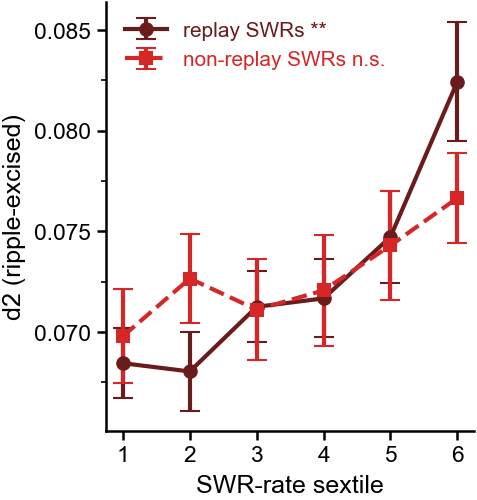

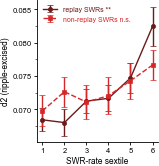

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import fig2_new_drawing as N            # fig2_new.py's drawing functions (copied)
N.LOGDIR = str(CSV)                        # they read their tables from this notebook's csv folder

# Each panel: the producer's own panel function, drawn under its native settings at the final figsize, then
# restyled for print by F.shrink (fonts 11/10/9 pt -> 6/5.5/5, lines x 0.5); only labels too long for the
# printed size are shortened.
W = pd.read_csv(os.path.join(N.LOGDIR, "excised_br_entropy_windows.csv"))

# ---- C: background d2 by replay-SWR / non-replay-SWR rate sextile
F.native_style()
fig, ax = plt.subplots(figsize=(42 * F.MM, 44 * F.MM), layout="constrained")
N.panel_replay_rates(ax, W)
ax.set_xlabel("SWR-rate sextile")                    # shortened; the legend distinguishes replay vs non-replay SWRs
# one block instead of two: each legend entry carries its line's own statistic; the separate coloured lines of
# text are removed (drop_counts then produces the formal legend without session counts)
stats = {t.get_text().split(":")[0]: t for t in ax.texts if ":" in t.get_text()}
for h, lab in zip(*ax.get_legend_handles_labels()):
    if lab in stats:
        h.set_label(stats[lab].get_text())
        stats[lab].remove()
ax.legend(frameon=False, loc="upper left")
F.shrink(fig)
for t in ax.get_legend().get_texts():               # legend text coloured to match its line
    t.set_color(N.RED if t.get_text().startswith("non") else N.DARK)
F.sparse_yticks(ax)                          # every other y label
F.settle(fig)
F.drop_counts(fig)                          # formal panel: no k/n; counts in the legend
F.show(F.save(fig, "Fig2_C_replay_vs_nonreplay_bgd2"))

## Fig 2D — per-SWR replay model, background d2

Log-odds of replay per SD of ripple-excised d2 (2024 Euclidean, AR p = 20), binomial model per session, with SWR rate, ripple amplitude and ripple duration added in turn; non-overlapping 30 s NREM windows, decoded time, 9 sessions.

- Data: `fig2f_swr_property_ladder.csv` (producer `fig2f_swr_property_ladder.py`); drawing `fig2_new.panel_ladder`.

saved figure_output\Fig2\Fig2_D_ripple_ladder_bgd2.svg / .png


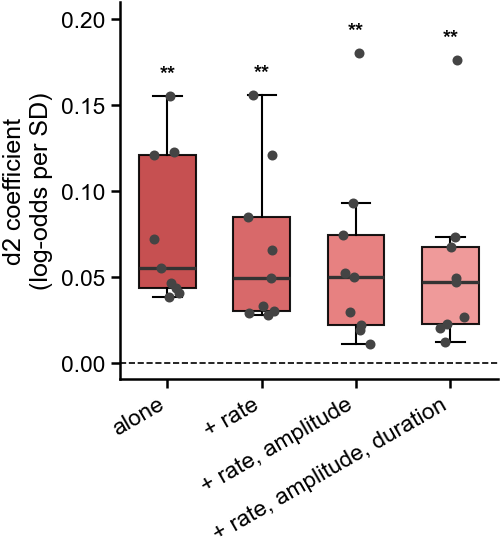

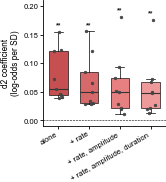

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import fig2_new_drawing as N            # fig2_new.py's drawing functions (copied)
N.LOGDIR = str(CSV)                        # they read their tables from this notebook's csv folder

# ---- D: per-SWR replay model ladder
F.native_style()
fig, ax = plt.subplots(figsize=(44 * F.MM, 48 * F.MM), layout="constrained")
N.panel_ladder(ax)
ax.set_ylabel("d2 coefficient\n(log-odds per SD)")  # shortened; the full description is in the caption
F.shrink(fig)
F.settle(fig)
F.drop_counts(fig)                          # formal panel: no k/n; counts in the legend
F.show(F.save(fig, "Fig2_D_ripple_ladder_bgd2"))

## Fig 2E — ablation of the background state variables

Replay rate per 30 s window (decoded NREM, 9 sessions): deviance explained lost when each background variable is dropped — ripple-excised d2 (2024 Euclidean), MUA, FR std (residualised on MUA) and E/I — mixed-model test; brackets: Holm-corrected pairwise p values.

- Producer: `fig2f_standalone.py` (`compute()`, `draw()`).

saved figure_output\Fig2\Fig2_E_ablation_bgd2.svg / .png


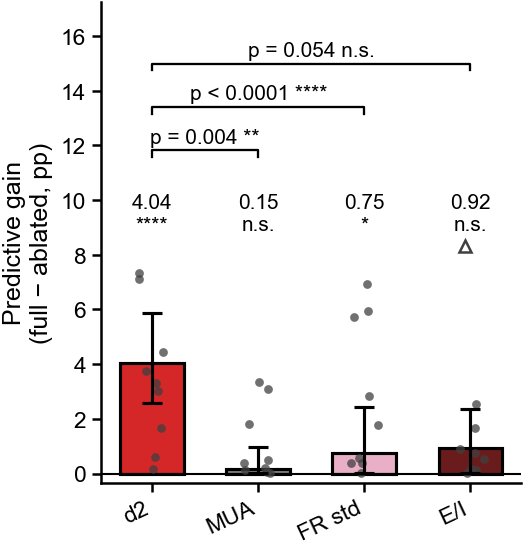

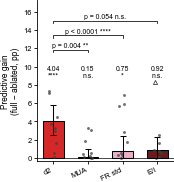

In [4]:
import matplotlib.pyplot as plt

# ---- E: ablation, mixed-model test (the closed Fig 2f)
import re
import fig2f_standalone_drawing as S_   # fig2f_standalone.py's draw() (copied)
from fig2f_standalone_drawing import draw
# the Fig 2 palette (d2 red, MUA grey, FR std pink, E/I brown) and plain predictor names ("FR std" is the FR std
# residualised on MUA, "(bg)" = ripple-excised background: both in the legend); y label "predictive gain"; no
# session name at the off-scale point (legend)
COLOR_E = {**S_.COLOR, "py_excised": N.RED, "MUA_bg": N.GREY, "FR_std_bg_res": N.PINK, "EI_bg": N.DARK}
LAB_E = {**S_.LAB, "py_excised_z": "d2", "MUA_bg_z": "MUA", "FR_std_bg_res_z": "FR std", "EI_bg_z": "E/I"}
_saved = S_.COLOR, S_.LAB, S_.star
S_.COLOR, S_.LAB = COLOR_E, LAB_E                    # draw() reads these module tables; restored right after
S_.star = F.stars                                    # four-level stars, restored right after
try:
    F.native_style()
    fig, ax = plt.subplots(figsize=(46 * F.MM, 48 * F.MM), layout="constrained")
    # ---- data (../csv) ----
    import types                                   # compute()'s result: the stored drop-one table + the mixed model
    D_E = dict(pooled=read_csv('fig2e_pooled.csv', index_col='predictor'),
               per=read_csv('fig2e_per_session.csv', index_col='session'),
               raw=list(read_csv('fig2e_predictors.csv').raw),
               r=types.SimpleNamespace(pvalues=read_csv('fig2e_lmm_pvalues.csv', index_col='term').p),
               con=[(t, None, None, None) for t in read_csv('fig2e_contrasts.csv').term],
               ph=list(read_csv('fig2e_contrasts.csv').p_holm))
    draw(ax, D_E, compact=True)
    # ---- the same from the recordings, with analysis_scripts/: ----
    # draw(ax, compute(), compact=True)
finally:
    S_.COLOR, S_.LAB, S_.star = _saved
for t in list(ax.texts):
    if t.get_text().startswith("PPP"):
        t.remove()                                   # "PPP8_day8: 10.7" (the triangle stays: off scale)
    elif t.get_text().startswith("p < 0.001 ****"):    # draw() writes "p < 0.001" for every p < 0.001
        t.set_text(t.get_text().replace("p < 0.001", "p < 0.0001"))
# the brackets keep every pairwise p value, including contrasts near the significance threshold
ax.set_ylabel("Predictive gain\n(full \u2212 ablated, pp)")
F.shrink(fig)
F.show(F.save(fig, "Fig2_E_ablation_bgd2"))